<a href="https://colab.research.google.com/github/San-Maansson/Stock_Analysis/blob/main/gbm_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
"""
XGBoost, LightGBM & CatBoost
Out-of-sample prediction
Next-day S&P 500 (^GSPC) returns
Walk-forward evaluation
"""
!pip install catboost
from dataclasses import dataclass
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

#Gradient boosting
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


/tmp/ipykernel_2826/2850969519.py:174: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("^GSPC", start="1990-01-01")
[*********************100%***********************]  1 of 1 completed


Streaming output truncated to the last 5000 lines.
[538]	validation_0-rmse:0.01191
[539]	validation_0-rmse:0.01191
[540]	validation_0-rmse:0.01191
[541]	validation_0-rmse:0.01191
[542]	validation_0-rmse:0.01191
[543]	validation_0-rmse:0.01191
[544]	validation_0-rmse:0.01191
[545]	validation_0-rmse:0.01191
[546]	validation_0-rmse:0.01191
[547]	validation_0-rmse:0.01191
[548]	validation_0-rmse:0.01191
[549]	validation_0-rmse:0.01191
[550]	validation_0-rmse:0.01191
[551]	validation_0-rmse:0.01191
[552]	validation_0-rmse:0.01191
[553]	validation_0-rmse:0.01191
[554]	validation_0-rmse:0.01191
[555]	validation_0-rmse:0.01191
[556]	validation_0-rmse:0.01191
[557]	validation_0-rmse:0.01191
[558]	validation_0-rmse:0.01191
[559]	validation_0-rmse:0.01191
[560]	validation_0-rmse:0.01191
[561]	validation_0-rmse:0.01191
[562]	validation_0-rmse:0.01191
[563]	validation_0-rmse:0.01191
[564]	validation_0-rmse:0.01191
[565]	validation_0-rmse:0.01191
[566]	validation_0-rmse:0.01191
[567]	validation_0-rm

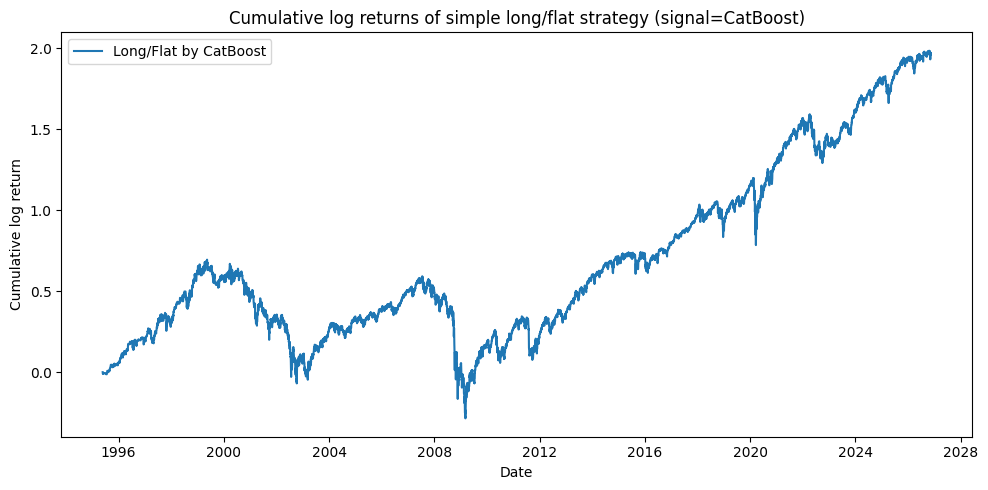


Saved: oos_summary.csv, oos_predictions_by_model.csv


In [5]:
#----------------------------------------------
#Feature engineering
#----------------------------------------------
def compute_features(df: pd.DataFrame, lags = 1):
    """
    Build a feature data matrix.
    Target y is next-day log return.
    """
    data = pd.DataFrame(index = df.index) #takes index
    data['ret'] = np.log(df['Close']).diff() #log return
    #Lags
    for k in range(1, lags+1):
        data[f'ret_lag_{k}'] = data['ret'].shift(k)

    #Rolling means and realised volatility
    for w in [5, 10, 20, 40]:
        data[f'roll_mean_{w}'] = data['ret'].rolling(w).mean()
        data[f'roll_std_{w}'] = data['ret'].rolling(w).std()

    #Calendar effects
    data['dow'] = data.index.dayofweek  #0=Mon, ..., 4=Fri
    data['month'] = data.index.month

    #Identify categorical columns for CatBoost
    cat_cols = ['dow', 'month']

    #Target: next-day return
    data['y'] = data['ret'].shift(-1) #lead

    #Drop missing values
    data = data.dropna()

    return data, cat_cols

#----------------------------------------------
#Metrics
#----------------------------------------------
@dataclass
class FoldMetrics():
    mse: float
    mae: float
    r2_oos: float
    dir_acc: float  #directional accuracy (% correct sign)
    n: int

def direction_accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return np.mean(np.sign(y_true) == np.sign(y_pred))

#----------------------------------------------
#Walk-forward evaluation
#----------------------------------------------
def walk_forward_eval(
    X: pd.DataFrame,
    y: pd.Series,
    models: Dict[str, object],
    cat_features_idx: List[int] | None = None,
    n_splits: int = 6,
) -> Tuple[pd.DataFrame, Dict[str, List[FoldMetrics]], pd.DataFrame]:
    """
    Expanding-window TimeSeriesSplit evaluation.
    Returns:
      - summary table (mean metrics),
      - per-fold metrics,
      - OOS predictions DataFrame with columns per model
    """
    tscv = TimeSeriesSplit(n_splits=n_splits, test_size=None)

    metrics: Dict[str, List[FoldMetrics]] = {name: [] for name in models}
    preds_oos = pd.DataFrame(index=y.index)

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        for name, model in models.items():
            # Clone / re-init model for each fold to avoid leakage
            if name == "XGBoost":
                m = XGBRegressor(
                    n_estimators=600,
                    max_depth=4,
                    learning_rate=0.03,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    reg_alpha=1.0,
                    reg_lambda=2.0,
                    random_state=42,
                    tree_method="hist",
                )
                m.fit(X_train, y_train, eval_set=[(X_test, y_test)])
                y_hat = m.predict(X_test)
            elif name == "LightGBM":
                m = LGBMRegressor(
                    n_estimators=800,
                    num_leaves=31,
                    max_depth=-1,
                    learning_rate=0.03,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    reg_alpha=0.5,
                    reg_lambda=1.0,
                    random_state=42,
                )
                m.fit(X_train, y_train, eval_set=[(X_test, y_test)])
                y_hat = m.predict(X_test)
            elif name == "CatBoost":
                #CatBoost can use categorical features by index (0-based)
                m = CatBoostRegressor(
                    iterations=700,
                    depth=6,
                    learning_rate=0.03,
                    l2_leaf_reg=3.0,
                    random_seed=42,
                    loss_function="RMSE"
                )
                if cat_features_idx:
                    m.fit(X_train, y_train, eval_set=(X_test, y_test), cat_features=cat_features_idx)
                else:
                    m.fit(X_train, y_train, eval_set=(X_test, y_test))
                y_hat = m.predict(X_test)
            else:
                raise ValueError(f"Unknown model {name}")

            #Collect metrics
            mse = mean_squared_error(y_test, y_hat)
            mae = mean_absolute_error(y_test, y_hat)
            #Out-of-sample R^2: computed against test-set mean
            ss_res = np.sum((y_test - y_hat) ** 2)
            ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
            r2_oos = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
            da = direction_accuracy(y_test.values, y_hat)

            metrics[name].append(FoldMetrics(mse, mae, r2_oos, da, len(y_test)))
            preds_oos.loc[y_test.index, name] = y_hat

    #Aggregate
    rows = []
    for name, lst in metrics.items():
        mse_mean = np.mean([m.mse for m in lst])
        mae_mean = np.mean([m.mae for m in lst])
        r2_mean = np.mean([m.r2_oos for m in lst])
        da_mean = np.mean([m.dir_acc for m in lst])
        rows.append([name, mse_mean, mae_mean, r2_mean, da_mean])

    summary = pd.DataFrame(rows, columns=["Model", "MSE", "MAE", "OOS_R2", "Directional_Accuracy"])\
                .sort_values(["OOS_R2", "Directional_Accuracy"], ascending=False)\
                .reset_index(drop=True)

    return summary, metrics, preds_oos

#----------------------------------------------
#Simple long/flat backtest
#----------------------------------------------

def simple_long_flat_backtest(ret: pd.Series, pred: pd.Series, thresh: float = 0.0) -> pd.Series:
    """
    Long if predicted return > thresh, flat otherwise.
    Returns cumulative log return series.
    """
    aligned = pd.concat([ret, pred], axis=1).dropna()
    aligned.columns = ['ret', 'pred']
    signal = (aligned['pred'] > thresh).astype(int)
    strat_ret = signal.shift(1).fillna(0) * aligned['ret']  # enter at next open (approx. using close-to-close)
    cum = strat_ret.cumsum()
    return cum


#----------------------------------------------
#Main function
#----------------------------------------------

def main():
    #Load data S&P 500
    print("Downloading from Yahoo Finance")
    df = yf.download("^GSPC", start="1990-01-01")
    if df.empty:
        raise RuntimeError("Failed to download data.")

    #Feature engineering
    data, cat_cols = compute_features(df)

    #Check data strcuture
    print(data.head())

    #Feature matrix and target
    feature_cols = [c for c in data.columns if c not in ['y']]
    X = data[feature_cols].copy()
    y = data['y'].copy()

    #Build categorical feature index list: CatBoost
    cat_idx = [feature_cols.index(c) for c in cat_cols if c in feature_cols]

    #Models
    models = {
        "XGBoost": None,
        "LightGBM": None,
        "CatBoost": None,
    }

    #Walk-forward evaluation
    print("Running walk-forward evaluation (TimeSeriesSplit)...")
    summary, per_fold, preds_oos = walk_forward_eval(X, y, models, cat_features_idx=cat_idx, n_splits=6)
    print("\nOut-of-sample metrics (averaged across folds):")
    print(summary.to_string(index=False))

    #Visualisation for the best model
    try:
        best_model = summary.iloc[0]['Model']
        print(f"\nTop model by OOS_R2/Direction: {best_model}")
        cum = simple_long_flat_backtest(data['y'], preds_oos[best_model])
        cum = cum.reindex(data.index).ffill()

        plt.figure(figsize=(10, 5))
        plt.plot(cum.index, cum.values, label=f"Long/Flat by {best_model}")
        plt.title(f"Cumulative log returns of simple long/flat strategy (signal={best_model})")
        plt.xlabel("Date")
        plt.ylabel("Cumulative log return")
        plt.legend()
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Plotting skipped due to: {e}")

    #Save outputs
    summary.to_csv("oos_summary.csv", index=False)
    preds_oos.to_csv("oos_predictions_by_model.csv")
    print("\nSaved: oos_summary.csv, oos_predictions_by_model.csv")


if __name__ == "__main__":
    main()